In [1]:
!pip install -U datasets huggingface_hub

  Using cached datasets-5.1.0-py3-none-any.whl.metadata (24 kB)
  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
  Using cached fsspec-2026.7.0-py3-none-any.whl.metadata (10 kB)
  Using cached hf_xet-1.7.1-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached truststore-0.10.5-py3-none-any.whl.metadata (4.5 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
Using cached datasets-5.1.0-py3-none-any.whl (604 kB)
   ---------------------------------------- 0.0/857.0 kB ? eta -:--:--
   ---------------------------------------- 857.0/857.0 kB 3.8 MB/s  0:00:00
Using cached dill-0.4.1-py3-none-any.whl (120 kB)
Using cached fsspec-2026.7.0-py3-none-any.whl (206 kB)
Using cached hf_xet-1.7.1-cp38-abi3-win_amd64.whl (3.8 MB)
Using cached anyio-4.15.1-py3-none-any.whl (132 

In [2]:
from huggingface_hub import snapshot_download

dataset_path = snapshot_download(
    repo_id="agyaatcoder/PlantDoc",
    repo_type="dataset",
    local_dir="PlantDoc"
)

print("Dataset downloaded successfully!")
print(dataset_path)

c:\Users\Khushi singh\Desktop\ml\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 5 files: 100%|██████████| 5/5 [04:42<00:00, 56.60s/it]

Dataset downloaded successfully!
C:\Users\Khushi singh\Desktop\agrisath AI\notebooks\PlantDoc


In [3]:
import os

for root, dirs, files in os.walk("PlantDoc"):
    print(root, "Files:", len(files))

PlantDoc Files: 2
PlantDoc\.cache Files: 0
PlantDoc\.cache\huggingface Files: 2
PlantDoc\.cache\huggingface\download Files: 2
PlantDoc\.cache\huggingface\download\data Files: 3
PlantDoc\.cache\huggingface\trees Files: 1
PlantDoc\data Files: 3


In [4]:
import os

data_path = "PlantDoc/data"

for file in os.listdir(data_path):
    file_path = os.path.join(data_path, file)

    print(file, "|", os.path.getsize(file_path) / (1024 * 1024), "MB")

test-00000-of-00001.parquet | 69.60366153717041 MB
train-00000-of-00002.parquet | 439.86665058135986 MB
train-00001-of-00002.parquet | 436.40778160095215 MB


In [5]:
for root, dirs, files in os.walk("PlantDoc/data"):
    for file in files:
        print(file)

test-00000-of-00001.parquet
train-00000-of-00002.parquet
train-00001-of-00002.parquet


In [6]:
#load the dataset
import pandas as pd
import os

data_path = "PlantDoc/data"

train_df1 = pd.read_parquet(
    os.path.join(data_path, "train-00000-of-00002.parquet")
)

train_df2 = pd.read_parquet(
    os.path.join(data_path, "train-00001-of-00002.parquet")
)

test_df = pd.read_parquet(
    os.path.join(data_path, "test-00000-of-00001.parquet")
)

print("Train 1:", train_df1.shape)
print("Train 2:", train_df2.shape)
print("Test:", test_df.shape)

Train 1: (1171, 5)
Train 2: (1171, 5)
Test: (236, 5)


In [7]:
train_df = pd.concat(
    [train_df1, train_df2],
    ignore_index=True
)

print("Total training images:", len(train_df))
print("Total testing images:", len(test_df))

Total training images: 2342
Total testing images: 236


In [9]:
print(train_df.columns.tolist())

['image_id', 'image', 'width', 'height', 'objects']


In [8]:
display(train_df.head())

,image_id,image,width,height,objects
0,0,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,350,300,"{'id': [0, 1, 2, 3], 'area': [17675, 17545, 17..."
1,4,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,1300,1099,"{'id': [4, 5, 6, 7], 'area': [95990, 187680, 1..."
2,8,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,1011,804,"{'id': [8, 9], 'area': [261516, 215441], 'bbox..."
3,12,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,500,383,"{'id': [12, 13], 'area': [90344, 37668], 'bbox..."
4,14,{'bytes': b'\xff\xd8\xff\xe1\x00\x18Exif\x00\x...,450,338,"{'id': [14, 15, 16, 17], 'area': [69336, 14570..."


In [10]:
# Inspect object annotations

sample = train_df.iloc[0]

print("Image ID:", sample["image_id"])
print("\nImage dimensions:")
print("Width:", sample["width"])
print("Height:", sample["height"])

print("\nObject annotations:")
print(sample["objects"])

Image ID: 0

Image dimensions:
Width: 350
Height: 300

Object annotations:
{'id': array([0, 1, 2, 3]), 'area': array([17675, 17545, 17967,  9480]), 'bbox': array([array([198.,  77., 101., 175.], dtype=float32),
       array([  3., 114., 145., 121.], dtype=float32),
       array([ 30., 184., 159., 113.], dtype=float32),
       array([226.,   4., 120.,  79.], dtype=float32)], dtype=object), 'category': array(['Cherry leaf', 'Cherry leaf', 'Cherry leaf', 'Cherry leaf'],
      dtype=object)}


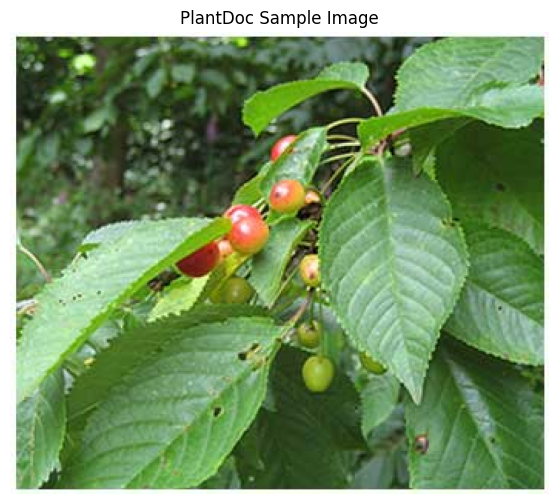

In [11]:
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

sample = train_df.iloc[0]

image_data = sample["image"]

img = Image.open(
    BytesIO(image_data["bytes"])
)

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title("PlantDoc Sample Image")
plt.axis("off")
plt.show()

In [12]:
print("Annotation keys:")
print(train_df.iloc[0]["objects"].keys())

print("\nImage annotation:")
for key, value in train_df.iloc[0]["objects"].items():
    print(key, ":", value)

Annotation keys:
dict_keys(['id', 'area', 'bbox', 'category'])

Image annotation:
id : [0 1 2 3]
area : [17675 17545 17967  9480]
bbox : [array([198.,  77., 101., 175.], dtype=float32)
 array([  3., 114., 145., 121.], dtype=float32)
 array([ 30., 184., 159., 113.], dtype=float32)
 array([226.,   4., 120.,  79.], dtype=float32)]
category : ['Cherry leaf' 'Cherry leaf' 'Cherry leaf' 'Cherry leaf']


In [13]:
from collections import Counter

class_counts = Counter()

for objects in train_df["objects"]:
    for category in objects["category"]:
        class_counts[category] += 1

print("Total number of classes:", len(class_counts))
print("\nClass-wise image object counts:")

for class_name, count in class_counts.most_common():
    print(f"{class_name}: {count}")

Total number of classes: 29

Class-wise image object counts:
Blueberry leaf: 827
Tomato leaf yellow virus: 787
Peach leaf: 610
Raspberry leaf: 539
Strawberry leaf: 462
Tomato Septoria leaf spot: 412
Tomato leaf: 369
Corn leaf blight: 358
Bell_pepper leaf: 312
Potato leaf early blight: 310
Tomato mold leaf: 277
Tomato leaf bacterial spot: 266
Bell_pepper leaf spot: 249
Squash Powdery mildew leaf: 248
Soyabean leaf: 246
Potato leaf late blight: 240
Apple leaf: 237
Tomato leaf mosaic virus: 225
Cherry leaf: 221
Tomato leaf late blight: 207
grape leaf: 205
Tomato Early blight leaf: 195
Apple rust leaf: 168
Apple Scab Leaf: 158
grape leaf black rot: 125
Corn rust leaf: 117
Corn Gray leaf spot: 75
Potato leaf: 11
Tomato two spotted spider mites leaf: 2


In [14]:
sample = train_df.iloc[0]

for bbox in sample["objects"]["bbox"]:
    x, y, width, height = bbox
    print(f"x={x}, y={y}, width={width}, height={height}")

x=198.0, y=77.0, width=101.0, height=175.0
x=3.0, y=114.0, width=145.0, height=121.0
x=30.0, y=184.0, width=159.0, height=113.0
x=226.0, y=4.0, width=120.0, height=79.0


In [15]:
# Create a list of all classes

class_names = sorted({
    category
    for objects in train_df["objects"]
    for category in objects["category"]
})

# Give every class a unique number

class_to_id = {
    name: index
    for index, name in enumerate(class_names)
}

# Display the classes

print("Total classes:", len(class_names))

for name, class_id in class_to_id.items():
    print(class_id, ":", name)

Total classes: 29
0 : Apple Scab Leaf
1 : Apple leaf
2 : Apple rust leaf
3 : Bell_pepper leaf
4 : Bell_pepper leaf spot
5 : Blueberry leaf
6 : Cherry leaf
7 : Corn Gray leaf spot
8 : Corn leaf blight
9 : Corn rust leaf
10 : Peach leaf
11 : Potato leaf
12 : Potato leaf early blight
13 : Potato leaf late blight
14 : Raspberry leaf
15 : Soyabean leaf
16 : Squash Powdery mildew leaf
17 : Strawberry leaf
18 : Tomato Early blight leaf
19 : Tomato Septoria leaf spot
20 : Tomato leaf
21 : Tomato leaf bacterial spot
22 : Tomato leaf late blight
23 : Tomato leaf mosaic virus
24 : Tomato leaf yellow virus
25 : Tomato mold leaf
26 : Tomato two spotted spider mites leaf
27 : grape leaf
28 : grape leaf black rot


In [16]:

import os

# Main dataset folder
base_dir = "PlantDoc_YOLO"

# Create folders
folders = [
    "images/train",
    "images/val",
    "images/test",
    "labels/train",
    "labels/val",
    "labels/test"
]

for folder in folders:
    path = os.path.join(base_dir, folder)
    os.makedirs(path, exist_ok=True)

print("YOLO folders created successfully!")

# Display the folder structure
for root, dirs, files in os.walk(base_dir):
    print(root)


YOLO folders created successfully!
PlantDoc_YOLO
PlantDoc_YOLO\images
PlantDoc_YOLO\images\test
PlantDoc_YOLO\images\train
PlantDoc_YOLO\images\val
PlantDoc_YOLO\labels
PlantDoc_YOLO\labels\test
PlantDoc_YOLO\labels\train
PlantDoc_YOLO\labels\val


In [17]:

from sklearn.model_selection import train_test_split

# Divide training dataset into train and validation
train_data, val_data = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42
)

print("Original training images:", len(train_df))
print("New training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_df))


Original training images: 2342
New training images: 1873
Validation images: 469
Testing images: 236


In [24]:

from pathlib import Path
from PIL import Image
from io import BytesIO

base_dir = Path("PlantDoc_YOLO")

def save_yolo_data(dataframe, split):

    corrected_count = 0
    skipped_count = 0

    for index, row in dataframe.iterrows():

        filename = f"{split}_{index}"

        # Read image
        image_bytes = row["image"]["bytes"]

        image = Image.open(
            BytesIO(image_bytes)
        ).convert("RGB")

        img_width, img_height = image.size

        # Save image
        image_path = (
            base_dir / "images" / split / f"{filename}.jpg"
        )
        image.save(image_path)

        # Create label file
        label_path = (
            base_dir / "labels" / split / f"{filename}.txt"
        )

        label_lines = []

        objects = row["objects"]

        for category, bbox in zip(
            objects["category"],
            objects["bbox"]
        ):

            class_id = class_to_id[category]

            # Original bounding box
            x, y, width, height = map(float, bbox)

            # Calculate box boundaries
            x1 = x
            y1 = y
            x2 = x + width
            y2 = y + height

            # Correct boundaries
            x1_new = max(0, min(x1, img_width))
            y1_new = max(0, min(y1, img_height))
            x2_new = max(0, min(x2, img_width))
            y2_new = max(0, min(y2, img_height))

            if (x1_new, y1_new, x2_new, y2_new) != (
                x1, y1, x2, y2
            ):
                corrected_count += 1

            # New dimensions
            new_width = x2_new - x1_new
            new_height = y2_new - y1_new

            # Skip invalid boxes
            if new_width <= 0 or new_height <= 0:
                skipped_count += 1
                continue

            # Convert into YOLO format
            center_x = (
                (x1_new + x2_new) / 2
            ) / img_width

            center_y = (
                (y1_new + y2_new) / 2
            ) / img_height

            norm_width = new_width / img_width
            norm_height = new_height / img_height

            label_lines.append(
                f"{class_id} {center_x:.6f} "
                f"{center_y:.6f} {norm_width:.6f} "
                f"{norm_height:.6f}"
            )

        # Save labels
        with open(label_path, "w") as file:
            file.write("\n".join(label_lines))

    print(f"\n{split} dataset updated!")
    print("Corrected boxes:", corrected_count)
    print("Skipped boxes:", skipped_count)


# Update all datasets
save_yolo_data(train_data, "train")
save_yolo_data(val_data, "val")
save_yolo_data(test_df, "test")



train dataset updated!
Corrected boxes: 11
Skipped boxes: 2

val dataset updated!
Corrected boxes: 0
Skipped boxes: 0

test dataset updated!
Corrected boxes: 0
Skipped boxes: 0


In [25]:

from pathlib import Path

base_dir = Path("PlantDoc_YOLO")

for split in ["train", "val", "test"]:

    image_folder = base_dir / "images" / split
    label_folder = base_dir / "labels" / split

    images = list(image_folder.glob("*.jpg"))
    labels = list(label_folder.glob("*.txt"))

    image_names = {p.stem for p in images}
    label_names = {p.stem for p in labels}

    missing_labels = image_names - label_names
    missing_images = label_names - image_names

    print(f"\n{split.upper()} DATASET")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Images without labels:", len(missing_labels))
    print("Labels without images:", len(missing_images))



TRAIN DATASET
Images: 1873
Labels: 1873
Images without labels: 0
Labels without images: 0

VAL DATASET
Images: 469
Labels: 469
Images without labels: 0
Labels without images: 0

TEST DATASET
Images: 236
Labels: 236
Images without labels: 0
Labels without images: 0


In [26]:
label_file = list(
    (base_dir / "labels" / "train").glob("*.txt")
)[0]

print("Label file:", label_file.name)

with open(label_file, "r") as file:
    print(file.read())

Label file: train_0.txt
6 0.710000 0.548333 0.288571 0.583333
6 0.215714 0.581667 0.414286 0.403333
6 0.312857 0.801667 0.454286 0.376667
6 0.817143 0.145000 0.342857 0.263333


In [27]:
invalid_annotations = []

for split in ["train", "val", "test"]:

    label_folder = base_dir / "labels" / split

    for label_file in label_folder.glob("*.txt"):

        with open(label_file, "r") as file:

            for line_number, line in enumerate(file, 1):

                values = line.strip().split()

                if len(values) != 5:
                    invalid_annotations.append(
                        (label_file.name, line_number, "Wrong format")
                    )
                    continue

                class_id, cx, cy, width, height = map(float, values)

                if not (
                    class_id.is_integer()
                    and 0 <= class_id < len(class_names)
                    and 0 <= cx <= 1
                    and 0 <= cy <= 1
                    and 0 < width <= 1
                    and 0 < height <= 1
                    and cx - width / 2 >= -1e-6
                    and cy - height / 2 >= -1e-6
                    and cx + width / 2 <= 1 + 1e-6
                    and cy + height / 2 <= 1 + 1e-6
                ):
                    invalid_annotations.append(
                        (label_file.name, line_number, "Invalid values")
                    )

print("Invalid annotations:", len(invalid_annotations))
print("Examples:", invalid_annotations[:10])

Invalid annotations: 0
Examples: []


In [28]:

import yaml

data_config = {
    "path": str(base_dir.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(class_names),
    "names": class_names
}

yaml_path = base_dir / "data.yaml"

with open(yaml_path, "w") as file:
    yaml.dump(data_config, file, sort_keys=False)

print("data.yaml created successfully!")
print("\nFile location:", yaml_path.resolve())


data.yaml created successfully!

File location: C:\Users\Khushi singh\Desktop\agrisath AI\notebooks\PlantDoc_YOLO\data.yaml


In [29]:
with open(yaml_path, "r") as file:
    print(file.read())

path: C:\Users\Khushi singh\Desktop\agrisath AI\notebooks\PlantDoc_YOLO
train: images/train
val: images/val
test: images/test
nc: 29
names:
- Apple Scab Leaf
- Apple leaf
- Apple rust leaf
- Bell_pepper leaf
- Bell_pepper leaf spot
- Blueberry leaf
- Cherry leaf
- Corn Gray leaf spot
- Corn leaf blight
- Corn rust leaf
- Peach leaf
- Potato leaf
- Potato leaf early blight
- Potato leaf late blight
- Raspberry leaf
- Soyabean leaf
- Squash Powdery mildew leaf
- Strawberry leaf
- Tomato Early blight leaf
- Tomato Septoria leaf spot
- Tomato leaf
- Tomato leaf bacterial spot
- Tomato leaf late blight
- Tomato leaf mosaic virus
- Tomato leaf yellow virus
- Tomato mold leaf
- Tomato two spotted spider mites leaf
- grape leaf
- grape leaf black rot

